# Aggregate the precipitation associated with the mesoscale features over the VicWaCI regions

In [ ]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from datetime import datetime
from dask.distributed import Client
import geopandas as gp
import matplotlib.pyplot as plt
import numpy as np
import regionmask
import xarray as xr

In [2]:
client = Client()

In [3]:
path_features = "/g/data/xv83/as3189/vicwaci/data/mesoscale_features"
path_fig = "/g/data/xv83/as3189/vicwaci/figures/mesoscale_features/"
path_attr = "/g/data/xv83/as3189/vicwaci/data/precip_attribution"

In [ ]:
var_map = dict(
    F="Fronts only",
    M="MTAs only",
    C="Cyclones only (surface)",
    V="Cyclones only (500 hPa)",
    FM="Fronts and MTAs",
    CF="Fronts and Cyclones (surface)",
    VF="Fronts and Cyclones (500 hPa)",
    CV="Cyclones (surface & 500 hPa)",
    CM="MTAs and Cyclones (surface)",
    VM="MTAs and Cyclones (500 hPa)",
    CVF="Fronts and Cyclones (surface & 500 hPa)",
    CVM="MTAs and Cyclones (surface & 500 hPa)",
    CFM="Fronts, MTAs and Cyclones (surface)",
    VFM="Fronts, MTAs and Cyclones (500 hPa)",
    CVFM="Fronts, MTAs and Cyclones (surface & 500 hPa)",
    U="Unclassified",
)

In [ ]:
valid_regions = [
    "victoria",
    "north_east_victoria",
    "north_west_victoria",
    "south_east_victoria",
    "south_west_victoria",
]


def read_shapefile(region_name):
    assert region_name in valid_regions
    gdf = gp.read_file(f"/g/data/xv83/dbi599/vicwaci/shapefiles/{region_name}.shp")
    region = regionmask.from_geopandas(gdf)

    return region


def plot_frac(frac):
    fig = plt.figure(figsize=[8, 4])
    ax = fig.add_subplot(111, projection=ccrs.PlateCarree())
    frac.plot(ax=ax, transform=ccrs.PlateCarree())
    ax.coastlines()
    ax.add_feature(cfeature.STATES)
    plt.show()


def spatial_sum(ds, region_name, outfile=None, freq="D"):
    """Calculate spatial mean"""

    region = read_shapefile(region_name)
    frac = region.mask_3D_frac_approx(ds).isel(region=0)

    weights = np.cos(np.deg2rad(ds["lat"]))
    ds_spatial_sum = ds.copy()
    for var in ds.data_vars:
        ds_spatial_sum[var] = ds[var].weighted(frac * weights).sum(dim=("lat", "lon"))

    # spatial_sum = np.round(spatial_sum, decimals=2)
    ds_spatial_sum = ds_spatial_sum.drop_vars(["region", "abbrevs", "names"])

    ds_spatial_sum["time"].attrs = {
        "axis": "T",
        "standard_name": "time",
        "long_name": "time",
    }
    if freq == "D":
        freq_long_name = "daily"
    else:
        freq_long_name = "monthly"

    ds_spatial_sum.attrs[
        "description"
    ] += f" Total {freq_long_name} precipitation summed over the {region_name} region."

    ds_spatial_sum.attrs["history"] = (
        ds.attrs["history"]
        + f"\n{datetime.now().strftime('%Y-%m-%d %H:%M:%S')}: Precipitation resampled to {freq_long_name} sum and summed over {region_name} region."
    )
    encoding = {
        "time": {"_FillValue": None},
    }
    for var in ds_spatial_sum.data_vars:
        ds_spatial_sum[var].attrs["units"] = "mm"
        ds_spatial_sum[var].attrs[
            "long_name"
        ] = f"Spatial sum of total {freq_long_name} precipitation"
        encoding[var] = {"_FillValue": None, "zlib": True, "complevel": 4, "shuffle": True}

    if outfile is not None:
        plot_frac(frac)
        ds_spatial_sum.to_netcdf(
            outfile,
            compute=True,
            encoding=encoding,
        )

    return ds_spatial_sum

In [6]:
dtlist = xr.date_range("1980-01-01", "2022-12-01", freq="1MS")
cyc_minprominence = 30
ds = xr.open_dataset(
    f"{path_attr}/ERA5_precip_attribution_{dtlist[0].year}-{dtlist[-1].year}_vic_min{cyc_minprominence}gpm.nc",
    chunks="auto",
)
ds

<xarray.Dataset> Size: 22GB
Dimensions:    (time: 125648, latitude: 31, longitude: 41)
Coordinates:
  * time       (time) datetime64[ns] 1MB 1980-01-01 ... 2022-12-31T21:00:00
  * latitude   (latitude) float32 124B -30.0 -30.5 -31.0 ... -44.0 -44.5 -45.0
  * longitude  (longitude) float32 164B 135.0 135.5 136.0 ... 154.0 154.5 155.0
Data variables: (12/17)
    U          (time, latitude, longitude) float64 1GB dask.array<chunksize=(63070, 14, 19), meta=np.ndarray>
    M          (time, latitude, longitude) float64 1GB dask.array<chunksize=(63070, 14, 19), meta=np.ndarray>
    F          (time, latitude, longitude) float64 1GB dask.array<chunksize=(63070, 14, 19), meta=np.ndarray>
    FM         (time, latitude, longitude) float64 1GB dask.array<chunksize=(63070, 14, 19), meta=np.ndarray>
    V          (time, latitude, longitude) float64 1GB dask.array<chunksize=(63070, 14, 19), meta=np.ndarray>
    VM         (time, latitude, longitude) float64 1GB dask.array<chunksize=(63070, 14, 19), meta=np.ndarray>
    ...         ...
    CFM        (time, latitude, longitude) float64 1GB dask.array<chunksize=(63070, 14, 19), meta=np.ndarray>
    CV         (time, latitude, longitude) float64 1GB dask.array<chunksize=(63070, 14, 19), meta=np.ndarray>
    CVM        (time, latitude, longitude) float64 1GB dask.array<chunksize=(63070, 14, 19), meta=np.ndarray>
    CVF        (time, latitude, longitude) float64 1GB dask.array<chunksize=(63070, 14, 19), meta=np.ndarray>
    CVFM       (time, latitude, longitude) float64 1GB dask.array<chunksize=(63070, 14, 19), meta=np.ndarray>
    total      (time, latitude, longitude) float64 1GB dask.array<chunksize=(63070, 14, 19), meta=np.ndarray>
Attributes:
    description:  Precipitation attribution to weather features (cyclones, fr...
    history:      2026-09-14 15:39:48 by 1.6.1-7-g2e093da\n2026-09-14 23:46:5...

In [ ]:
ds = ds.rename({"longitude": "lon", "latitude": "lat"})
ds_daily = ds.resample(time="d").sum()
ds_monthly = ds.resample(time="1MS").sum()
ds_daily

<xarray.Dataset> Size: 3GB
Dimensions:  (time: 15706, lat: 31, lon: 41)
Coordinates:
  * time     (time) datetime64[ns] 126kB 1980-01-01 1980-01-02 ... 2022-12-31
  * lat      (lat) float32 124B -30.0 -30.5 -31.0 -31.5 ... -44.0 -44.5 -45.0
  * lon      (lon) float32 164B 135.0 135.5 136.0 136.5 ... 154.0 154.5 155.0
Data variables: (12/17)
    U        (time, lat, lon) float64 160MB dask.array<chunksize=(7884, 14, 19), meta=np.ndarray>
    M        (time, lat, lon) float64 160MB dask.array<chunksize=(7884, 14, 19), meta=np.ndarray>
    F        (time, lat, lon) float64 160MB dask.array<chunksize=(7884, 14, 19), meta=np.ndarray>
    FM       (time, lat, lon) float64 160MB dask.array<chunksize=(7884, 14, 19), meta=np.ndarray>
    V        (time, lat, lon) float64 160MB dask.array<chunksize=(7884, 14, 19), meta=np.ndarray>
    VM       (time, lat, lon) float64 160MB dask.array<chunksize=(7884, 14, 19), meta=np.ndarray>
    ...       ...
    CFM      (time, lat, lon) float64 160MB dask.array<chunksize=(7884, 14, 19), meta=np.ndarray>
    CV       (time, lat, lon) float64 160MB dask.array<chunksize=(7884, 14, 19), meta=np.ndarray>
    CVM      (time, lat, lon) float64 160MB dask.array<chunksize=(7884, 14, 19), meta=np.ndarray>
    CVF      (time, lat, lon) float64 160MB dask.array<chunksize=(7884, 14, 19), meta=np.ndarray>
    CVFM     (time, lat, lon) float64 160MB dask.array<chunksize=(7884, 14, 19), meta=np.ndarray>
    total    (time, lat, lon) float64 160MB dask.array<chunksize=(7884, 14, 19), meta=np.ndarray>
Attributes:
    description:  Precipitation attribution to weather features (cyclones, fr...
    history:      2026-09-14 15:39:48 by 1.6.1-7-g2e093da\n2026-09-14 23:46:5...

# Generate daily files

/g/data/xv83/as3189/vicwaci/data/era5_mesoscale_features_precip_total_victoria_daily_1980-2022.nc


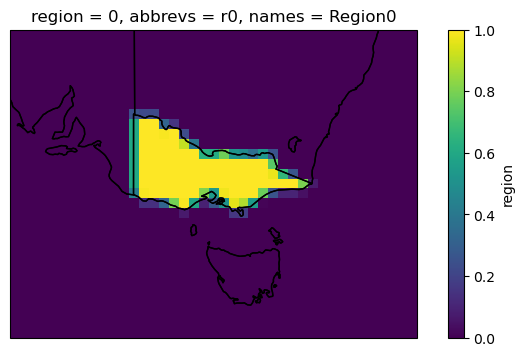

/g/data/xv83/as3189/vicwaci/data/era5_mesoscale_features_precip_total_north-east-victoria_daily_1980-2022.nc


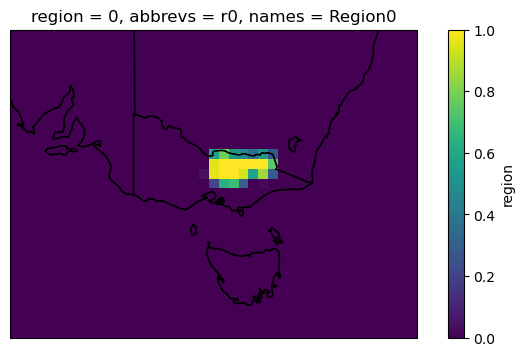

/g/data/xv83/as3189/vicwaci/data/era5_mesoscale_features_precip_total_north-west-victoria_daily_1980-2022.nc


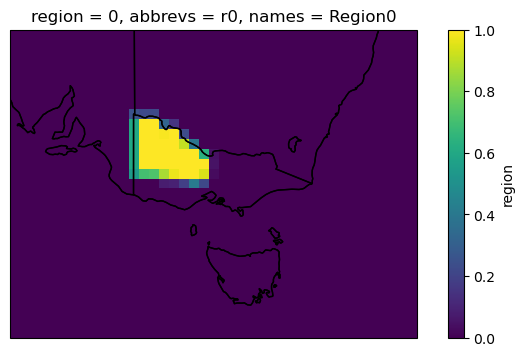

/g/data/xv83/as3189/vicwaci/data/era5_mesoscale_features_precip_total_south-east-victoria_daily_1980-2022.nc


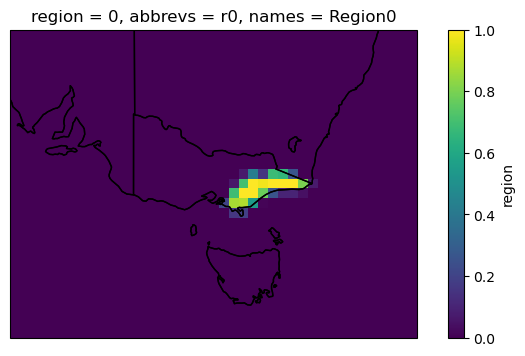

/g/data/xv83/as3189/vicwaci/data/era5_mesoscale_features_precip_total_south-west-victoria_daily_1980-2022.nc


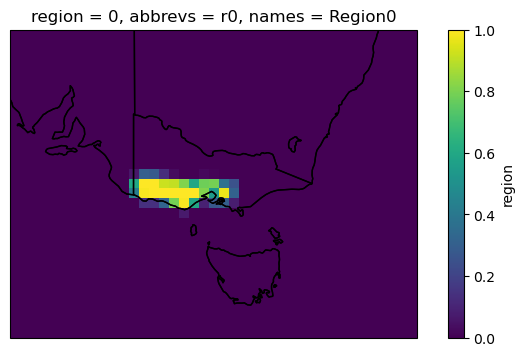

In [ ]:
for region_name in valid_regions:
    region_fname = region_name.replace("_", "-")
    y1, y2 = [int(y) for y in ds_daily.time[[0, -1]].dt.year]
    outfile = f"/g/data/xv83/as3189/vicwaci/data/era5_mesoscale_features_precip_total_{region_fname}_daily_{y1}-{y2}.nc"
    print(outfile)
    ds_spatial_sum = spatial_sum(ds_daily, region_name, outfile, freq="D")

# Generate monthly files

/g/data/xv83/as3189/vicwaci/data/precip_attribution/era5_mesoscale_features_precip_total_victoria_monthly_1980-2022.nc


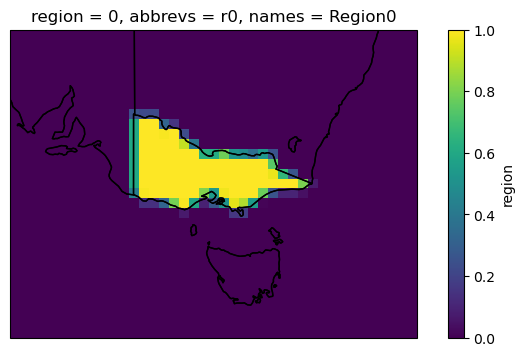

/g/data/xv83/as3189/vicwaci/data/precip_attribution/era5_mesoscale_features_precip_total_north-east-victoria_monthly_1980-2022.nc


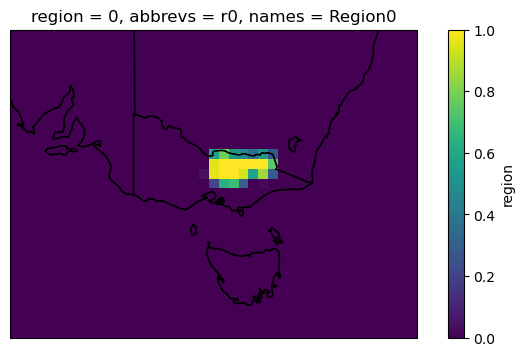

/g/data/xv83/as3189/vicwaci/data/precip_attribution/era5_mesoscale_features_precip_total_north-west-victoria_monthly_1980-2022.nc


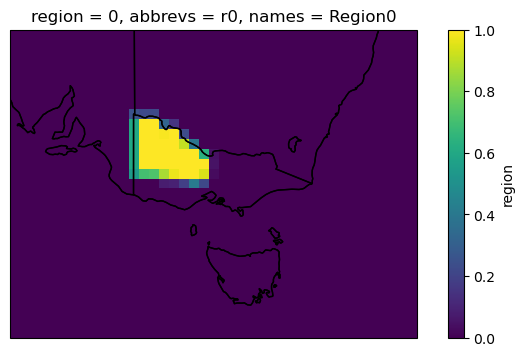

/g/data/xv83/as3189/vicwaci/data/precip_attribution/era5_mesoscale_features_precip_total_south-east-victoria_monthly_1980-2022.nc


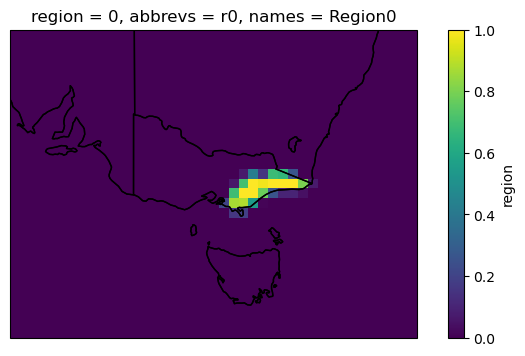

/g/data/xv83/as3189/vicwaci/data/precip_attribution/era5_mesoscale_features_precip_total_south-west-victoria_monthly_1980-2022.nc


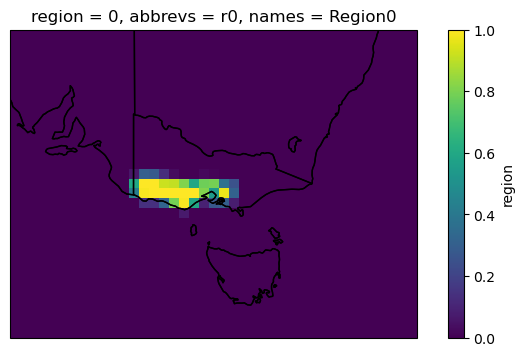

In [ ]:
for region_name in valid_regions:
    region_fname = region_name.replace("_", "-")
    y1, y2 = [int(y) for y in ds_monthly.time[[0, -1]].dt.year]
    outfile = (
        f"{path_attr}/era5_mesoscale_features_precip_total_{region_fname}_monthly_{y1}-{y2}.nc"
    )
    print(outfile)
    ds_spatial_sum = spatial_sum(ds_monthly, region_name, outfile, freq="M")

## Plot timeseries to show data

In [ ]:
region_name = valid_regions[0]
dx = spatial_sum(ds_monthly, region_name, freq="M")
dx

<xarray.Dataset> Size: 75kB
Dimensions:  (time: 516, lat: 31, lon: 41)
Coordinates:
  * time     (time) datetime64[ns] 4kB 1980-01-01 1980-02-01 ... 2022-12-01
  * lat      (lat) float32 124B -30.0 -30.5 -31.0 -31.5 ... -44.0 -44.5 -45.0
  * lon      (lon) float32 164B 135.0 135.5 136.0 136.5 ... 154.0 154.5 155.0
Data variables: (12/17)
    U        (time) float64 4kB dask.array<chunksize=(259,), meta=np.ndarray>
    M        (time) float64 4kB dask.array<chunksize=(259,), meta=np.ndarray>
    F        (time) float64 4kB dask.array<chunksize=(259,), meta=np.ndarray>
    FM       (time) float64 4kB dask.array<chunksize=(259,), meta=np.ndarray>
    V        (time) float64 4kB dask.array<chunksize=(259,), meta=np.ndarray>
    VM       (time) float64 4kB dask.array<chunksize=(259,), meta=np.ndarray>
    ...       ...
    CFM      (time) float64 4kB dask.array<chunksize=(259,), meta=np.ndarray>
    CV       (time) float64 4kB dask.array<chunksize=(259,), meta=np.ndarray>
    CVM      (time) float64 4kB dask.array<chunksize=(259,), meta=np.ndarray>
    CVF      (time) float64 4kB dask.array<chunksize=(259,), meta=np.ndarray>
    CVFM     (time) float64 4kB dask.array<chunksize=(259,), meta=np.ndarray>
    total    (time) float64 4kB dask.array<chunksize=(259,), meta=np.ndarray>
Attributes:
    description:  Precipitation attribution to weather features (cyclones, fr...
    history:      2026-09-14 15:39:48 by 1.6.1-7-g2e093da\n2026-09-14 23:46:5...

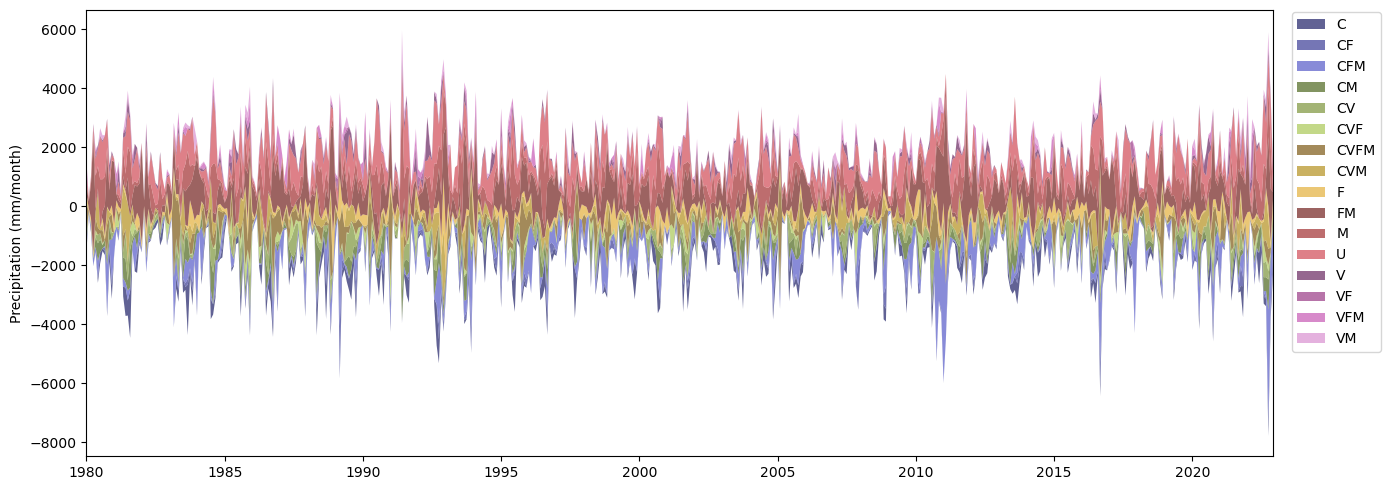

In [ ]:
# Plot timeseries of monthly pr attributed to each feature combo (stacked)
var_list = sorted([var for var in dx.data_vars if var not in ["total"]])
colors = plt.colormaps["tab20b"](np.linspace(0, 1, len(var_list)))

fig, ax = plt.subplots(figsize=(14, 5))
ax.stackplot(
    dx.time,
    [dx[var] for var in var_list],
    labels=var_list,
    alpha=0.8,
    baseline="wiggle",
    colors=colors,
)
ax.set_xmargin(0)
ax.set_ylabel("Precipitation (mm/month)")
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1.01))
plt.tight_layout()

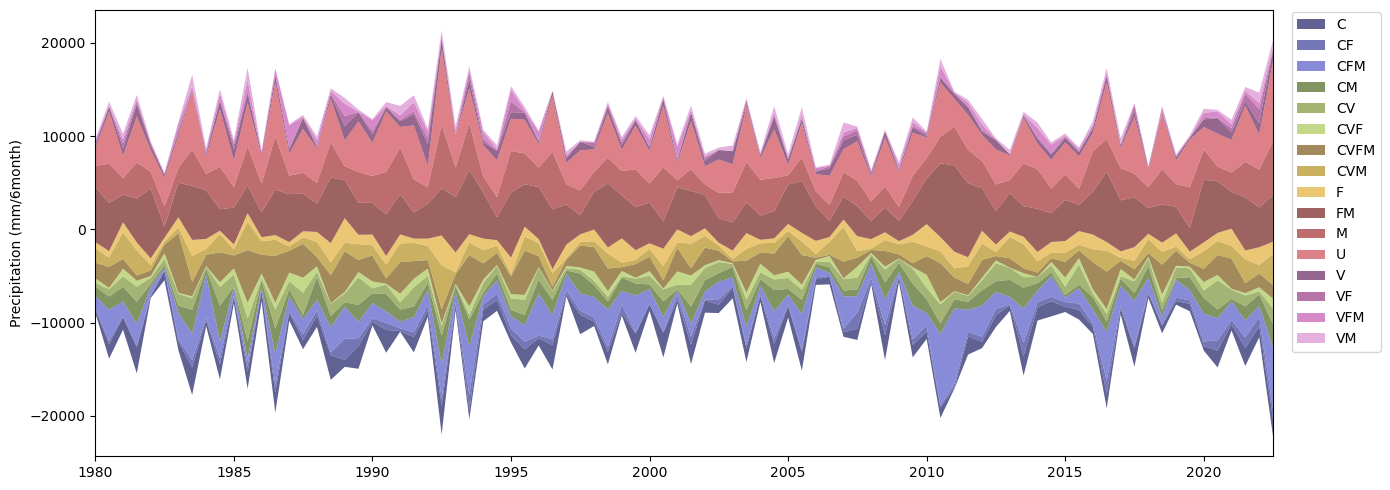

In [ ]:
# Plot timeseries of 6? monthly pr attributed to each feature combo (stacked)
dxx = dx.resample(time="6MS").sum()

var_list = sorted([var for var in dx.data_vars if var not in ["total"]])
colors = plt.colormaps["tab20b"](np.linspace(0, 1, len(var_list)))

fig, ax = plt.subplots(figsize=(14, 5))
ax.stackplot(
    dxx.time,
    [dxx[var] for var in var_list],
    labels=var_list,
    alpha=0.8,
    baseline="wiggle",
    colors=colors,
)
ax.set_xmargin(0)
ax.set_ylabel("Precipitation (mm/6month)")
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1.01))
plt.tight_layout()